# Amazon Engineering Challenge — AVL × Red-Black (LLRB)

## Análise experimental completa: inserção, busca e remoção

Para fazer a comparação entre os algoritmos de Árvore Binária Auto-Balanceada (AVL) e Árvore Binária Rubro-Negra caída para a esquerda (variação LLRB), serão realizados experimentos onde ambos os algoritmos de árvore receberão exatamente os mesmos valores, mesma sequência de operações e mesma quantidade de elementos.

Para tanto, temos como parâmetros de número de elementos e operações:

**Tamanhos das Árvores:** 100, 500, 1.000, 10.000 e 50.000 elementos.  
**Operações (tanto inserções quanto remoções):** crescente (*Increasing*), decrescente (*Decreasing*) e aleatória (*Random*).  

Para cada tamanho de árvore, o algoritmo será executado uma quantidade pré-determinada de vezes de modo que árvores maiores executem menos repetições enquanto árvores menores sejam executadas mais vezes (essa escolha foi necessária para diminuir o tempo de execução do notebook). O motivo das múltiplas excuções é poder analisar a média dos tempos obtidos, obtendo um resultado mais estável. **O tempo vai ser analisado para as operações de busca, inserção e remoção.**

Os demais elementos a serem analisados são o número de rotações, a altura e, para a rubro-negra, a inversão de cores que são contabilizadas separadamente na inserção e na remoção. **Observação: como a AVL não possui inversão de cores, esse parâmetro será representado por `NaN`, e não zero.**

### Procedimento de cada repetição:

1. Construir **novas instâncias** AVL e LLRB, com sequências idênticas.
2. Medir exclusivamente a inserção (sem geração de dados, validação ou desenho de gráficos).
3. Validar ordenação e invariantes fora da medição.
4. Medir buscas bem-sucedidas e malsucedidas.
5. Medir a remoção de todos os nós **na mesma ordem em que foram inseridos**; isso é uma escolha experimental e pode ser alterada em análises futuras.
6. Validar árvore vazia e resultados após a remoção.



## 1. Configuração e bibliotecas


In [28]:
from pathlib import Path
from time import perf_counter_ns
import gc
import random
import platform
import sys

import matplotlib.pyplot as plt
import pandas as pd

from structures.avl import AVLTree
from structures.RB import RedBlackTree

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("Working directory:", Path.cwd())
print("AVL:", AVLTree.__name__, "| LLRB:", RedBlackTree.__name__)

Python: 3.11.16
OS: Windows-10-10.0.26200-SP0
Working directory: C:\Users\Gabriel\OneDrive\Documentos\Faculdade e cursos\UFRN\EDB\amazon_engineering_challenge
AVL: AVLTree | LLRB: RedBlackTree


## 2. Configuração dos Parâmetros 

In [29]:
SIZES = [100, 500, 1_000, 10_000, 50_000]
REPEATS_BY_SIZE = {100: 25, 500: 20, 1_000: 15, 10_000: 10, 50_000: 5}
SEED = 42
SCENARIOS = ["Increasing", "Decreasing", "Random"]
TREE_CLASSES = [("AVL", AVLTree), ("LLRB", RedBlackTree)]

VALIDATE_EACH_RUN = True


def generate_sequences(n, seed=SEED):
    values = list(range(1, n + 1))
    shuffled = values.copy()
    random.Random(seed).shuffle(shuffled)
    return {
        "Increasing": values,
        "Decreasing": values[::-1],
        "Random": shuffled,
    }

print("Scenarios:", list(generate_sequences(10)))
print("Repetitions:", REPEATS_BY_SIZE)

Scenarios: ['Increasing', 'Decreasing', 'Random']
Repetitions: {100: 25, 500: 20, 1000: 15, 10000: 10, 50000: 5}


## 3. Verificação inicial das classes

*smoke test* detecta possíveis erros nas classes AVL e RB antes de executar os testes grandes. 

In [30]:
def is_valid_tree(tree):
    if isinstance(tree, AVLTree):
        return tree.is_valid_avl()
    if isinstance(tree, RedBlackTree):
        return tree.is_valid_rb()
    raise TypeError(f"Unsupported tree type: {type(tree)}")


def check_tree_state(tree, expected_values):
    assert is_valid_tree(tree), f"Invalid {type(tree).__name__}"
    assert tree.in_order() == sorted(expected_values), "Incorrect in-order traversal"
    assert tree.count_nodes() == len(expected_values), "Incorrect node count"


for name, tree_class in TREE_CLASSES:
    tree = tree_class()
    for value in [20, 10, 30, 5, 15]:
        assert tree.insert(value) is True
    check_tree_state(tree, [20, 10, 30, 5, 15])
    assert bool(tree.search(10))
    assert not bool(tree.search(999))
    assert tree.remove(10) is True
    check_tree_state(tree, [20, 30, 5, 15])
    assert tree.remove(999) is False
    print(f"{name}: initial checks passed")

AVL: initial checks passed
LLRB: initial checks passed


## 4. Função de benchmark completo

A mesma função executa os três tipos de operação (inserção, remoção e busca) nas duas classes. Em cada repetição criamos uma árvore nova para não contaminar os resultados com operações anteriores.

Para reduzir interferência, o teste executa uma chamada de aquecimento curta antes das séries e coleta o tempo bruto em nanossegundos. 

In [31]:
def benchmark_run(tree_class, tree_label, values, scenario, n, repetition):
    tree = tree_class()
    expected = sorted(values)
    missing_values = list(range(n + 1, 2 * n + 1))

    # INSERT: only insert operations are timed.
    start = perf_counter_ns()
    for value in values:
        tree.insert(value)
    insertion_ns = perf_counter_ns() - start

    insertion_height = tree.height()
    insertion_rotations = tree.rotations
    insertion_flips = getattr(tree, "color_flips", float("nan"))

    if VALIDATE_EACH_RUN:
        check_tree_state(tree, expected)

    # SUCCESSFUL SEARCH: every stored value is searched exactly once.
    found_count = 0
    start = perf_counter_ns()
    for value in values:
        if tree.search(value):
            found_count += 1
    success_search_ns = perf_counter_ns() - start
    assert found_count == n, f"Successful search failed: {tree_label}"

    # UNSUCCESSFUL SEARCH: all absent keys exceed the largest stored key.
    missing_count = 0
    start = perf_counter_ns()
    for value in missing_values:
        if not tree.search(value):
            missing_count += 1
    failed_search_ns = perf_counter_ns() - start
    assert missing_count == n, f"Unsuccessful search failed: {tree_label}"

    # REMOVE: delete in insertion order. Check correctness after timing.
    rotations_before = tree.rotations
    flips_before = getattr(tree, "color_flips", 0)
    removed_count = 0
    start = perf_counter_ns()
    for value in values:
        if tree.remove(value):
            removed_count += 1
    removal_ns = perf_counter_ns() - start

    assert removed_count == n, f"Removal failed: {tree_label}"
    assert tree.root is None, f"Tree not empty after removals: {tree_label}"
    if VALIDATE_EACH_RUN:
        check_tree_state(tree, [])

    return {
        "Tree": tree_label,
        "Sequence": scenario,
        "Size": n,
        "Repetition": repetition,
        "Insertion_ms": insertion_ns / 1_000_000,
        "Search_success_ms": success_search_ns / 1_000_000,
        "Search_failure_ms": failed_search_ns / 1_000_000,
        "Removal_ms": removal_ns / 1_000_000,
        "Search_success_us_per_op": success_search_ns / n / 1_000,
        "Search_failure_us_per_op": failed_search_ns / n / 1_000,
        "Height_after_insert": insertion_height,
        "Insertion_rotations": insertion_rotations,
        "Removal_rotations": tree.rotations - rotations_before,
        "Insertion_color_flips": insertion_flips,
        "Removal_color_flips": (
            tree.color_flips - flips_before
            if hasattr(tree, "color_flips") else float("nan")
        ),
        "Valid": True,
    }

## 5. Rodada piloto (100 elementos)

Outro *smoke test*. Aqui será testado primeiro um caso de cada árvore pois, se houver `AssertionError` ou erro de import, já impede o programa de rodar a bateria completa de testes.

In [32]:
pilot_values = generate_sequences(100)["Random"]
pilot_rows = [
    benchmark_run(cls, label, pilot_values, "Random", 100, 1)
    for label, cls in TREE_CLASSES
]
pd.DataFrame(pilot_rows)[[
    "Tree", "Size", "Height_after_insert", "Insertion_rotations",
    "Insertion_ms", "Search_success_ms", "Removal_ms", "Valid"
]].round(4)

,Tree,Size,Height_after_insert,Insertion_rotations,Insertion_ms,Search_success_ms,Removal_ms,Valid
0,AVL,100,8,65,1.3911,0.0570,0.4334,True
1,LLRB,100,9,120,0.6035,0.0554,0.8994,True


## 6. Experimento completo: 100, 500, 1.000 e 10.000 nós


In [33]:
rows = []

for n in SIZES:
    sequences = generate_sequences(n)
    repeats = REPEATS_BY_SIZE[n]
    print(f"Running N={n:,} | {repeats} repetitions per tree and sequence", flush=True)

    for scenario in SCENARIOS:
        values = sequences[scenario]

        for repetition in range(1, repeats + 1):
            for label, tree_class in TREE_CLASSES:
                rows.append(
                    benchmark_run(tree_class, label, values, scenario, n, repetition)
                )

    print(f"  Completed N={n:,} | cumulative rows={len(rows)}", flush=True)

results_df = pd.DataFrame(rows)
assert len(results_df) == sum(3 * 2 * REPEATS_BY_SIZE[n] for n in SIZES)
assert results_df["Valid"].all()

print(f"Completed {len(results_df)} benchmark runs.")
results_df.head(8).round(4)

Running N=100 | 25 repetitions per tree and sequence
  Completed N=100 | cumulative rows=150
Running N=500 | 20 repetitions per tree and sequence
  Completed N=500 | cumulative rows=270
Running N=1,000 | 15 repetitions per tree and sequence
  Completed N=1,000 | cumulative rows=360
Running N=10,000 | 10 repetitions per tree and sequence
  Completed N=10,000 | cumulative rows=420
Running N=50,000 | 5 repetitions per tree and sequence
  Completed N=50,000 | cumulative rows=450
Completed 450 benchmark runs.


,Tree,Sequence,Size,Repetition,Insertion_ms,Search_success_ms,Search_failure_ms,Removal_ms,Search_success_us_per_op,Search_failure_us_per_op,Height_after_insert,Insertion_rotations,Removal_rotations,Insertion_color_flips,Removal_color_flips,Valid
0,AVL,Increasing,100,1,0.8195,0.0513,0.0514,0.3444,0.513,0.514,7,93,44,NaN,NaN,True
1,LLRB,Increasing,100,1,0.5093,0.0515,1.5396,0.6966,0.515,15.396,7,94,95,91.0,287.0,True
2,AVL,Increasing,100,2,0.6406,0.0524,0.0527,0.3501,0.524,0.527,7,93,44,NaN,NaN,True
3,LLRB,Increasing,100,2,0.4266,0.0508,0.0458,0.6836,0.508,0.458,7,94,95,91.0,287.0,True
4,AVL,Increasing,100,3,0.6038,0.0501,0.0515,0.3440,0.501,0.515,7,93,44,NaN,NaN,True
5,LLRB,Increasing,100,3,0.4268,0.0769,0.0466,0.6769,0.769,0.466,7,94,95,91.0,287.0,True
6,AVL,Increasing,100,4,0.6039,0.0502,0.0586,0.3438,0.502,0.586,7,93,44,NaN,NaN,True
7,LLRB,Increasing,100,4,0.4181,0.0501,0.0458,0.6706,0.501,0.458,7,94,95,91.0,287.0,True


## 7. Estatísticas consolidadas

Cálculo das médias, desvio-padrão e medianas para os tempos. Altura, rotações e inversões de cores não variam entre repetições quando a sequência é a mesma, portanto mostra-se apenas a primeira observação de cada grupo.

**Observação: `NaN` em `Color flips` para AVL significa *não aplicável*, não ausência de balanceamento.**

In [34]:
TIME_COLS = [
    "Insertion_ms", "Search_success_ms", "Search_failure_ms", "Removal_ms",
    "Search_success_us_per_op", "Search_failure_us_per_op",
]

aggregation = {}
for col in TIME_COLS:
    aggregation[f"{col}_mean"] = (col, "mean")
    aggregation[f"{col}_std"] = (col, "std")
    aggregation[f"{col}_median"] = (col, "median")

for col in [
    "Height_after_insert", "Insertion_rotations", "Removal_rotations",
    "Insertion_color_flips", "Removal_color_flips"
]:
    aggregation[col] = (col, "first")

summary_df = (
    results_df.groupby(["Size", "Sequence", "Tree"], as_index=False)
    .agg(**aggregation)
    .sort_values(["Size", "Sequence", "Tree"])
)

print("Consolidated results:")
display(summary_df.round(4))

Consolidated results:


,Size,Sequence,Tree,Insertion_ms_mean,Insertion_ms_std,Insertion_ms_median,Search_success_ms_mean,Search_success_ms_std,Search_success_ms_median,Search_failure_ms_mean,...,Search_success_us_per_op_std,Search_success_us_per_op_median,Search_failure_us_per_op_mean,Search_failure_us_per_op_std,Search_failure_us_per_op_median,Height_after_insert,Insertion_rotations,Removal_rotations,Insertion_color_flips,Removal_color_flips
0,100,Decreasing,AVL,0.6037,0.0192,0.5970,0.0517,0.0014,0.0511,0.0515,...,0.0140,0.5110,0.5149,0.0058,0.5140,7,93,44,NaN,NaN
1,100,Decreasing,LLRB,0.5464,0.0625,0.5190,0.1069,0.2124,0.0516,0.0470,...,2.1243,0.5160,0.4696,0.0410,0.4560,9,91,344,91.0,287.0
2,100,Increasing,AVL,0.6474,0.1057,0.6092,0.0580,0.0241,0.0508,0.0514,...,0.2408,0.5080,0.5142,0.0384,0.5140,7,93,44,NaN,NaN
3,100,Increasing,LLRB,0.4380,0.0466,0.4285,0.0516,0.0065,0.0507,0.1058,...,0.0648,0.5070,1.0585,2.9874,0.4550,7,94,95,91.0,287.0
4,100,Random,AVL,0.5705,0.0450,0.5591,0.0532,0.0011,0.0532,0.0523,...,0.0108,0.5320,0.5228,0.0111,0.5180,8,65,29,NaN,NaN
5,100,Random,LLRB,0.4840,0.0580,0.4621,0.0538,0.0012,0.0535,0.0465,...,0.0123,0.5350,0.4646,0.0095,0.4680,9,120,198,71.0,393.0
6,500,Decreasing,AVL,3.9378,0.1482,3.8608,0.2932,0.0115,0.2908,0.3725,...,0.0230,0.5816,0.7450,0.2942,0.6548,9,491,242,NaN,NaN
7,500,Decreasing,LLRB,4.0181,0.9085,3.6125,0.3066,0.0164,0.2997,0.3292,...,0.0329,0.5995,0.6584,0.1612,0.6038,14,486,2794,486.0,2334.0
8,500,Increasing,AVL,4.1714,0.2037,4.1316,0.3016,0.0398,0.2882,0.3320,...,0.0795,0.5764,0.6639,0.0416,0.6491,9,491,242,NaN,NaN
9,500,Increasing,LLRB,2.9800,0.2392,2.9288,0.3206,0.0743,0.2954,0.3189,...,0.1487,0.5908,0.6377,0.1030,0.6084,9,492,496,486.0,2334.0


## 8. Gráficos: alturas e operações de balanceamento

Esses gráficos usam as métricas determinísticas (altura, rotações e inversões de cores) para cada cenário.

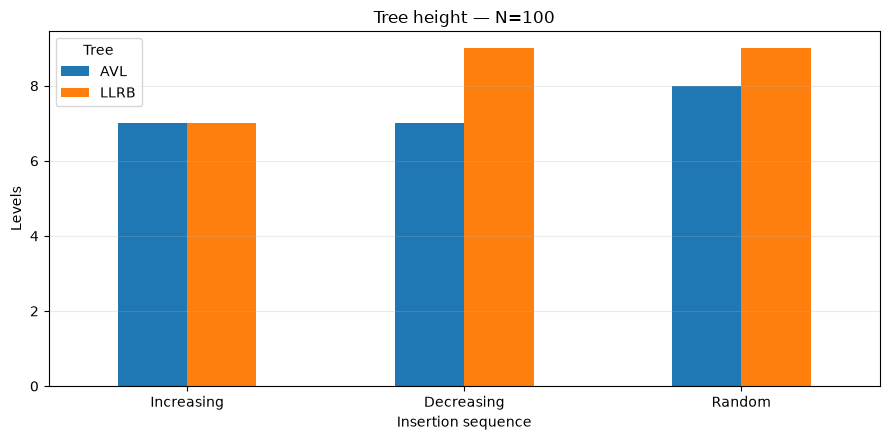

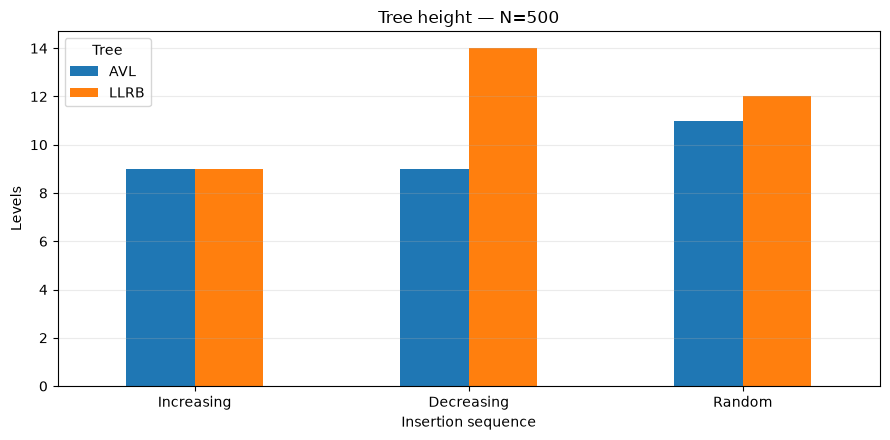

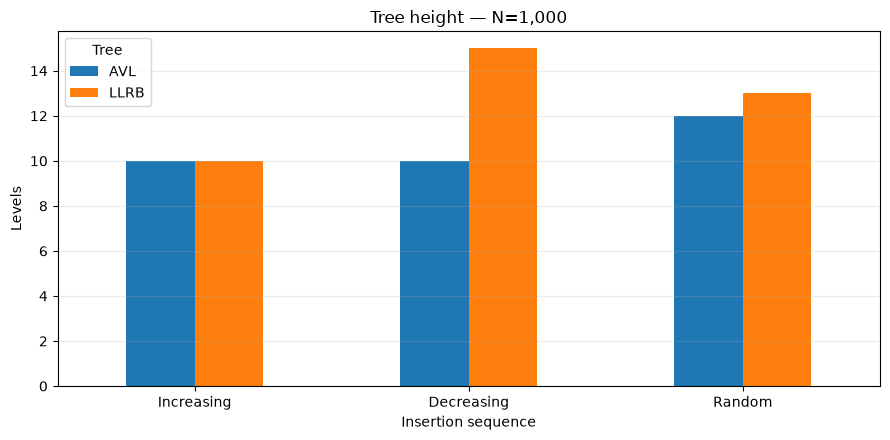

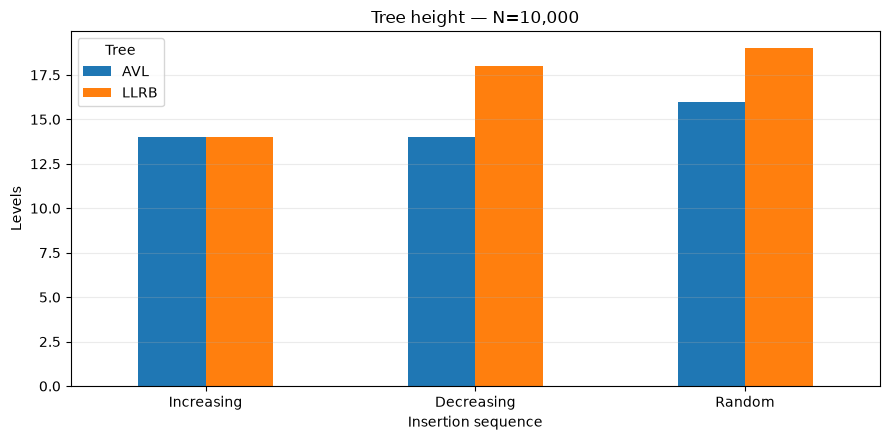

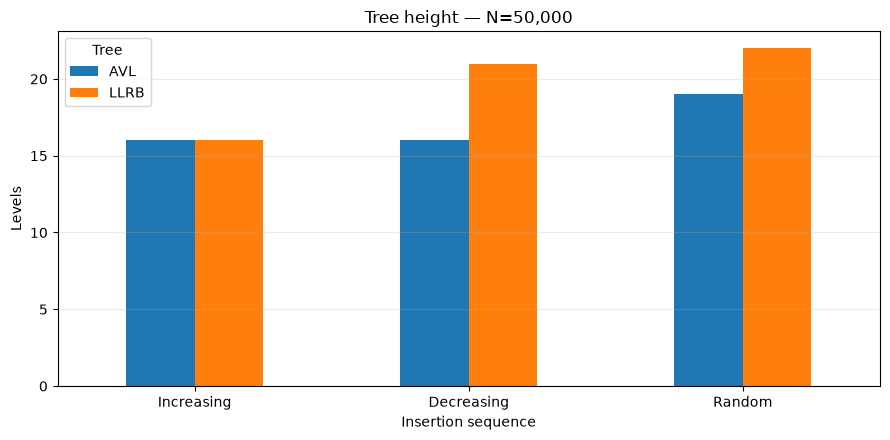

In [35]:
def plot_bars_by_scenario(df, metric, title, ylabel, size, include_llrb_only=False):
    frame = df[df["Size"] == size]
    if include_llrb_only:
        frame = frame[frame["Tree"] == "LLRB"]
    pivot = frame.pivot(index="Sequence", columns="Tree", values=metric)
    pivot = pivot.reindex(SCENARIOS)
    ax = pivot.plot(kind="bar", figsize=(9, 4.5), rot=0)
    ax.set_title(f"{title} — N={size:,}")
    ax.set_xlabel("Insertion sequence")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

for n in SIZES:
    plot_bars_by_scenario(summary_df, "Height_after_insert", "Tree height", "Levels", n)

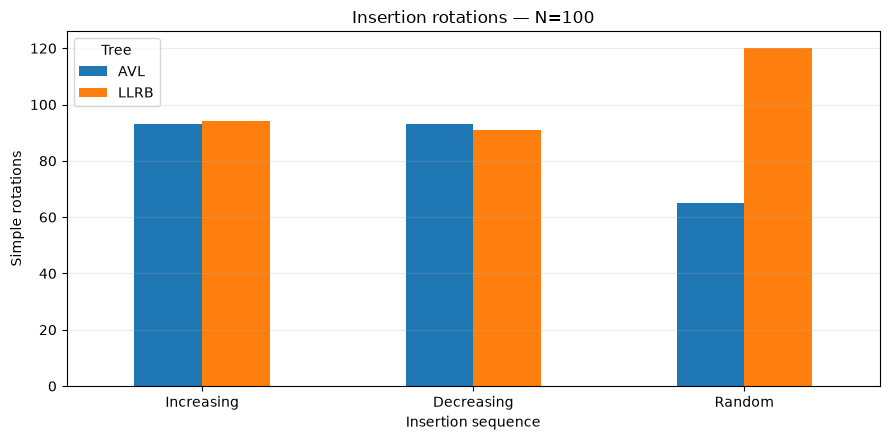

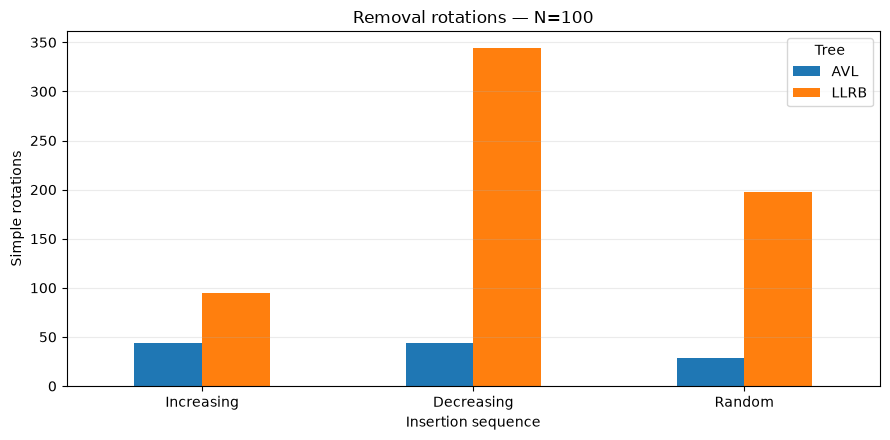

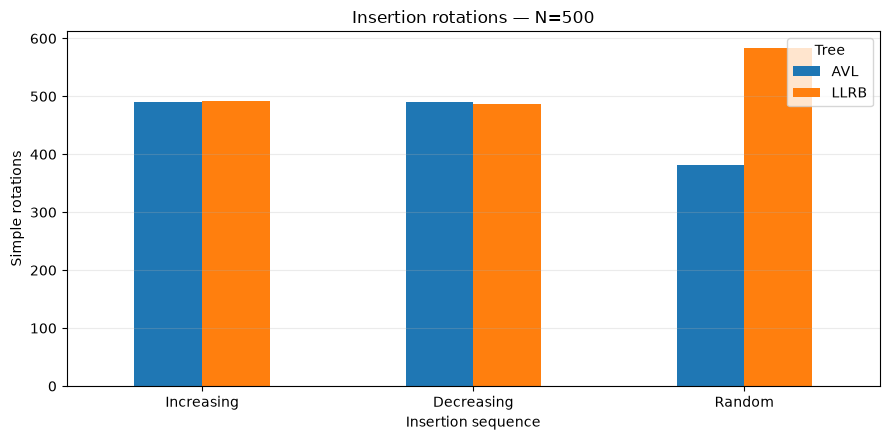

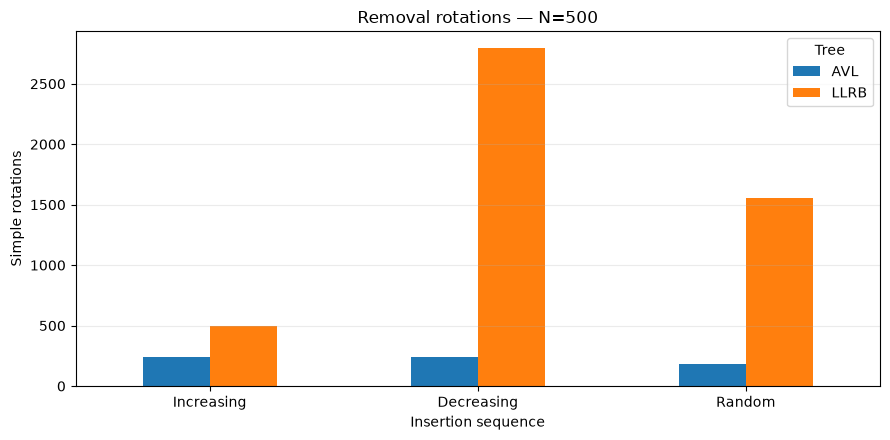

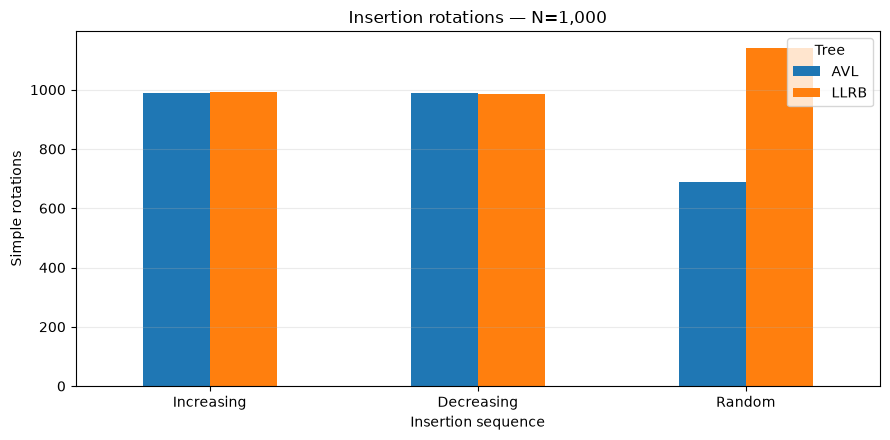

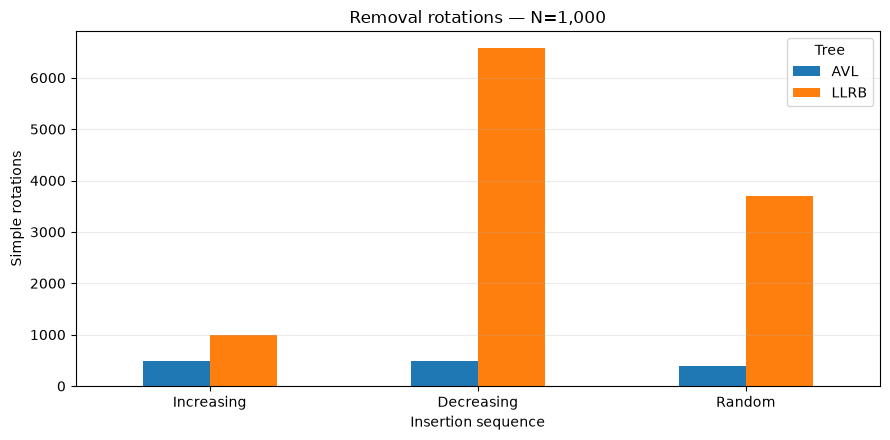

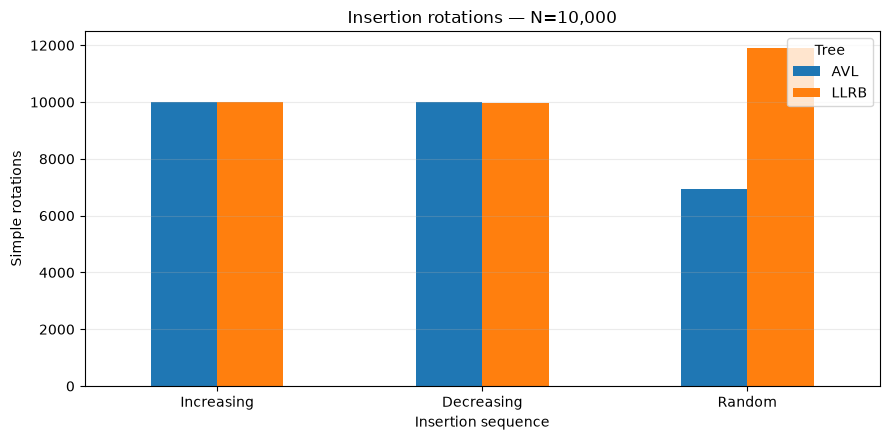

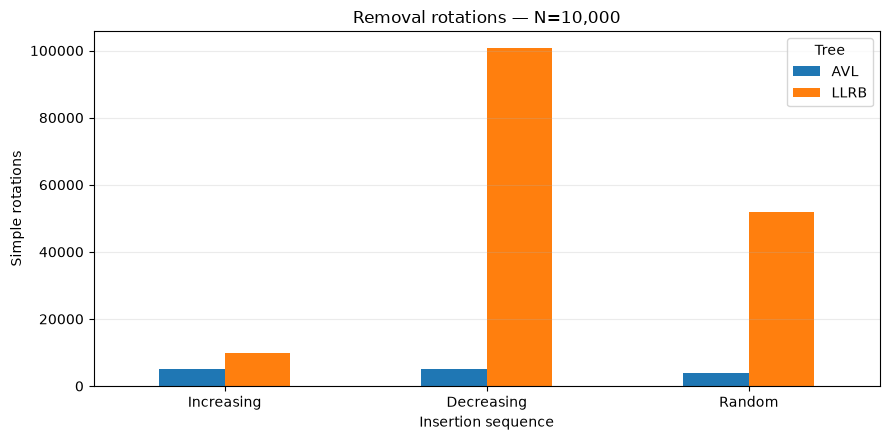

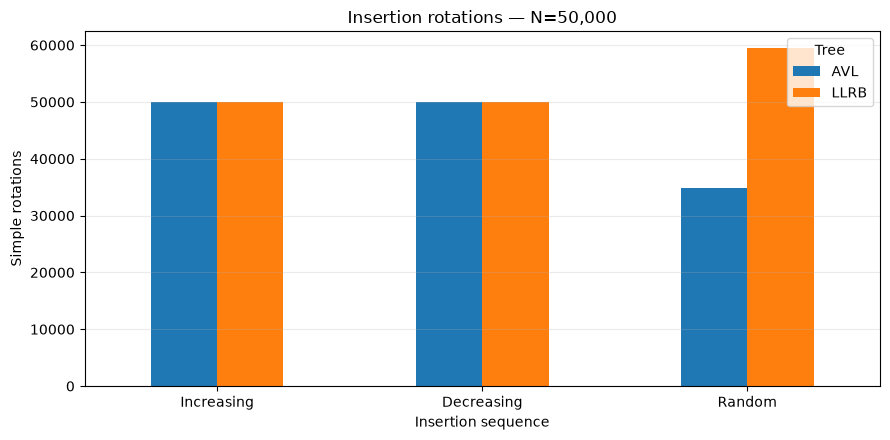

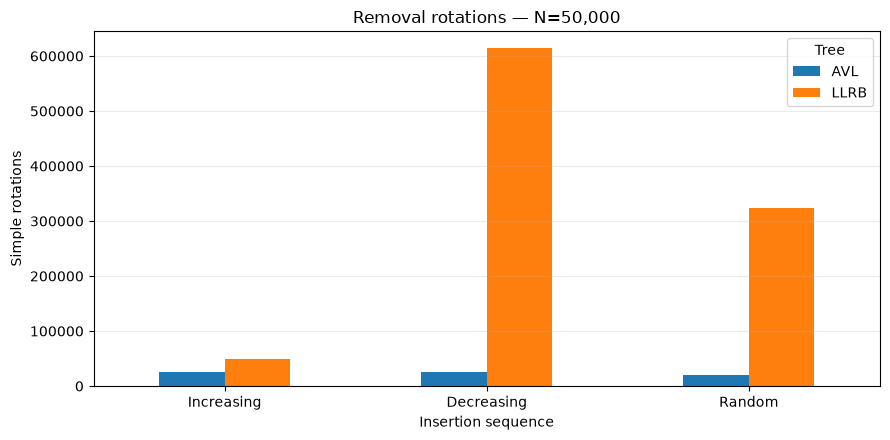

In [36]:
for n in SIZES:
    plot_bars_by_scenario(summary_df, "Insertion_rotations", "Insertion rotations", "Simple rotations", n)
    plot_bars_by_scenario(summary_df, "Removal_rotations", "Removal rotations", "Simple rotations", n)

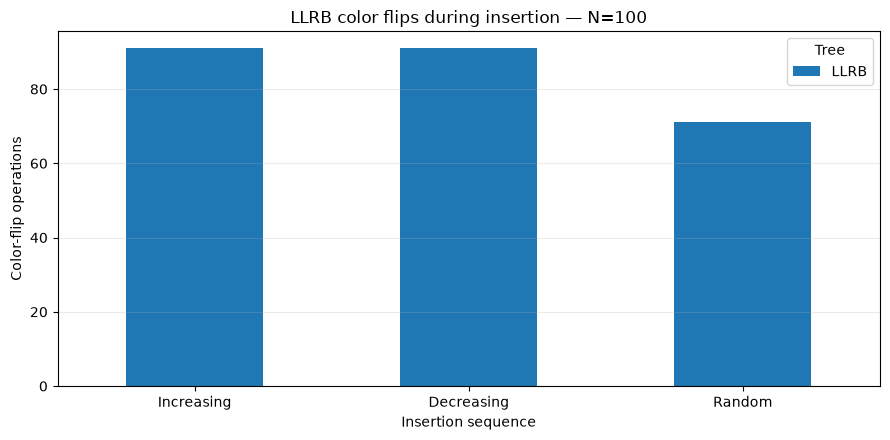

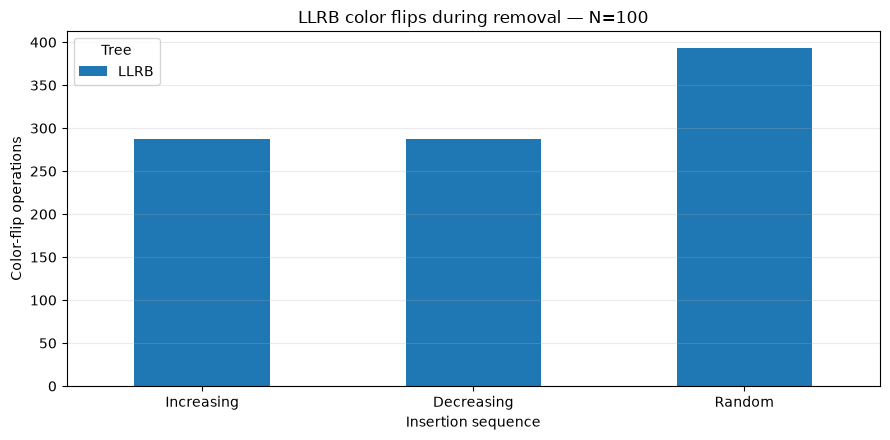

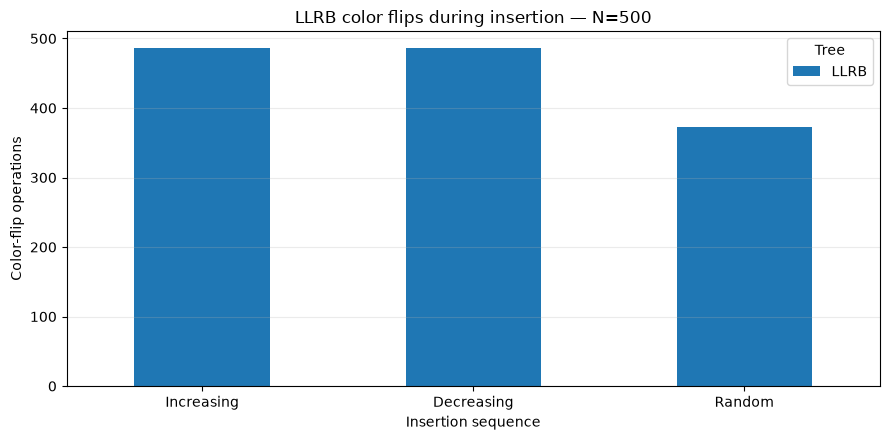

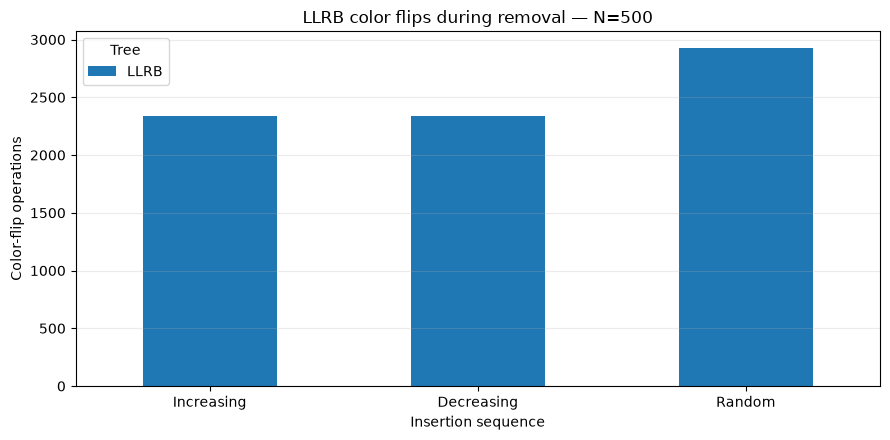

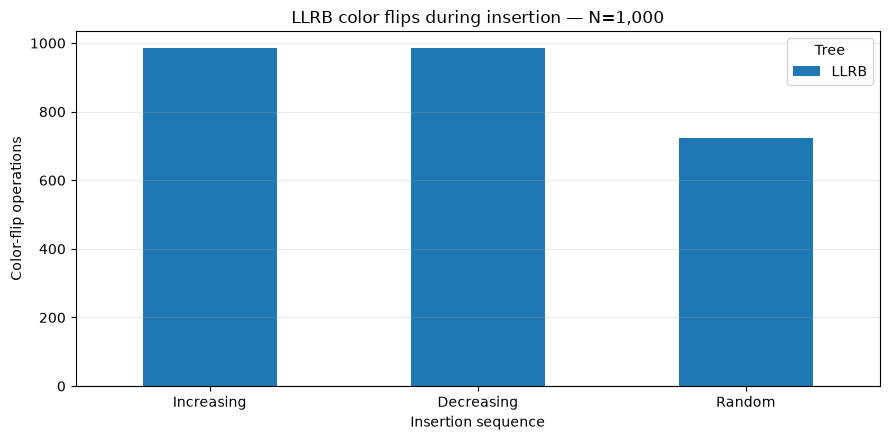

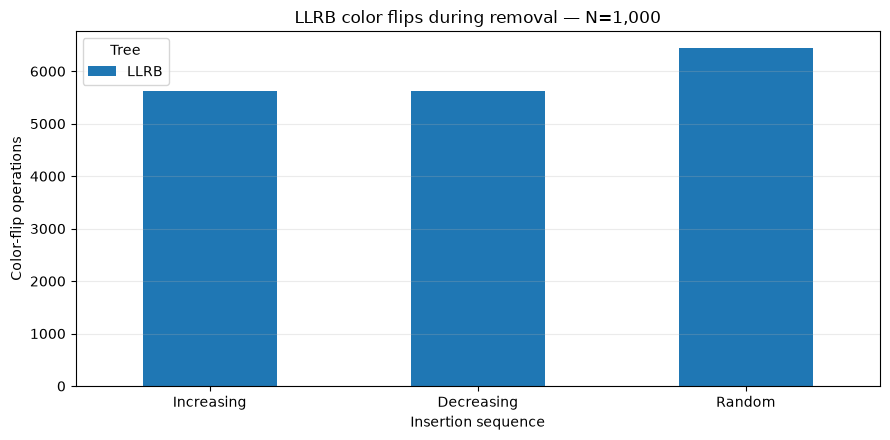

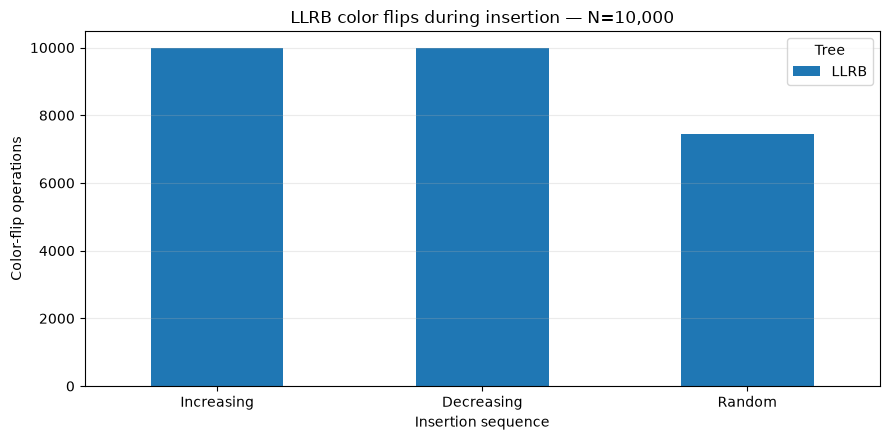

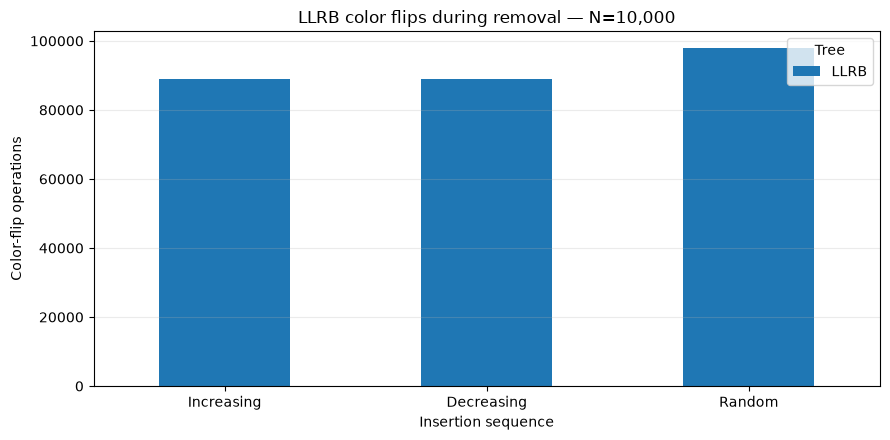

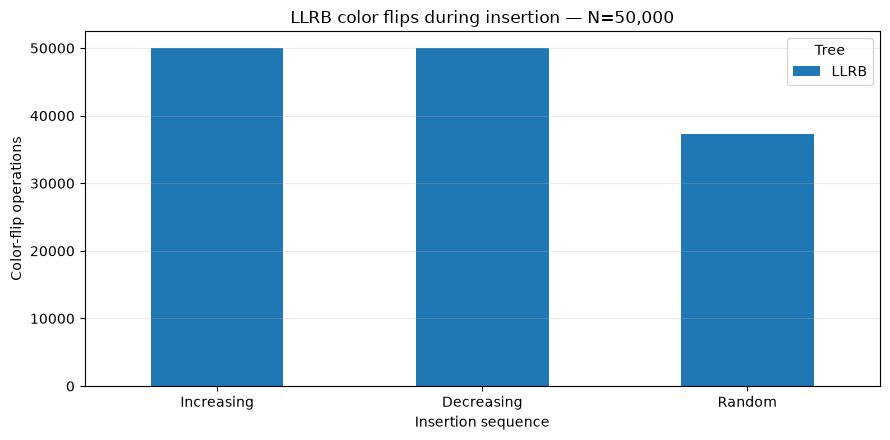

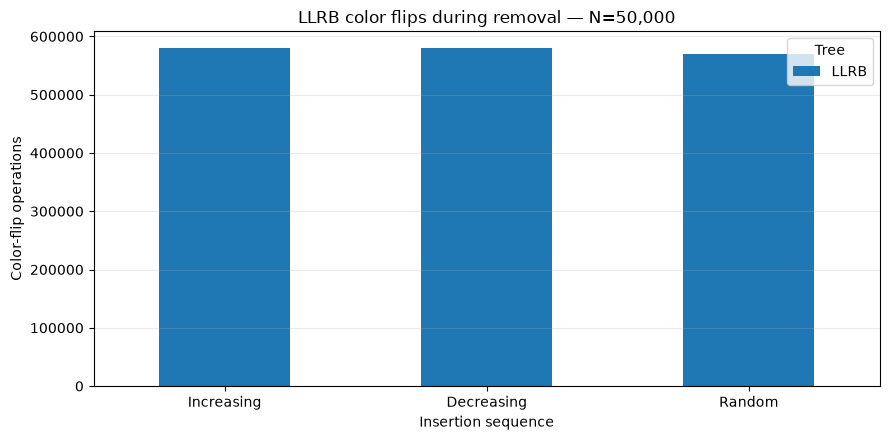

In [37]:
for n in SIZES:
    plot_bars_by_scenario(
        summary_df, "Insertion_color_flips", "LLRB color flips during insertion",
        "Color-flip operations", n, include_llrb_only=True
    )
    plot_bars_by_scenario(
        summary_df, "Removal_color_flips", "LLRB color flips during removal",
        "Color-flip operations", n, include_llrb_only=True
    )

## 9. Gráficos: tempo de inserção, busca e remoção


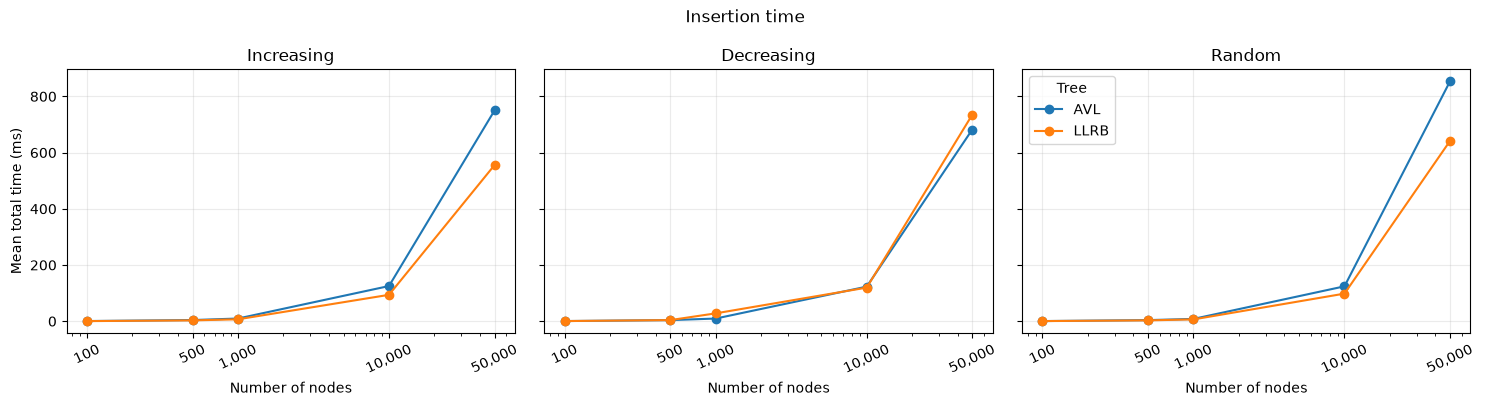

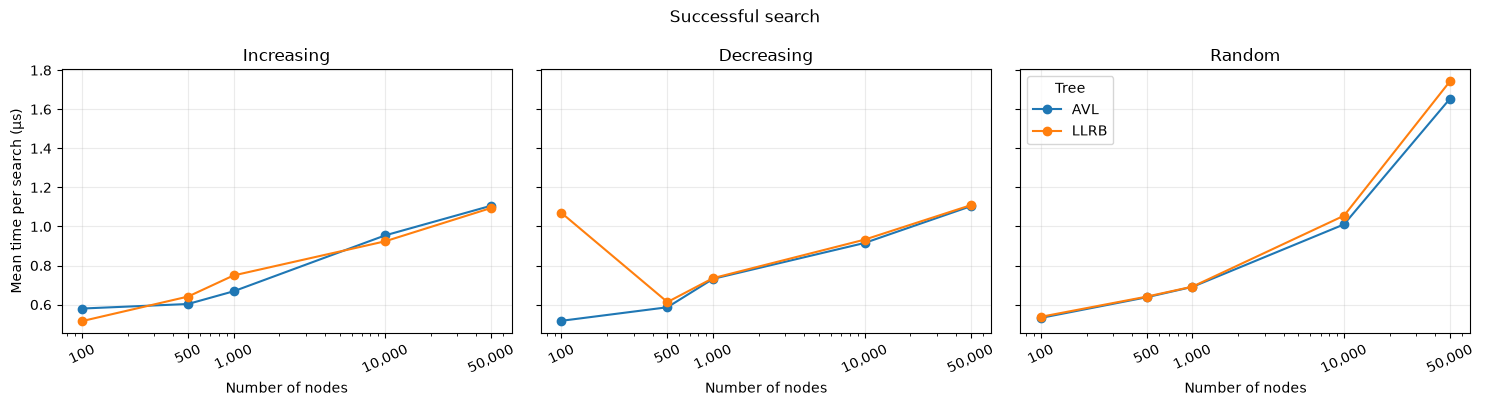

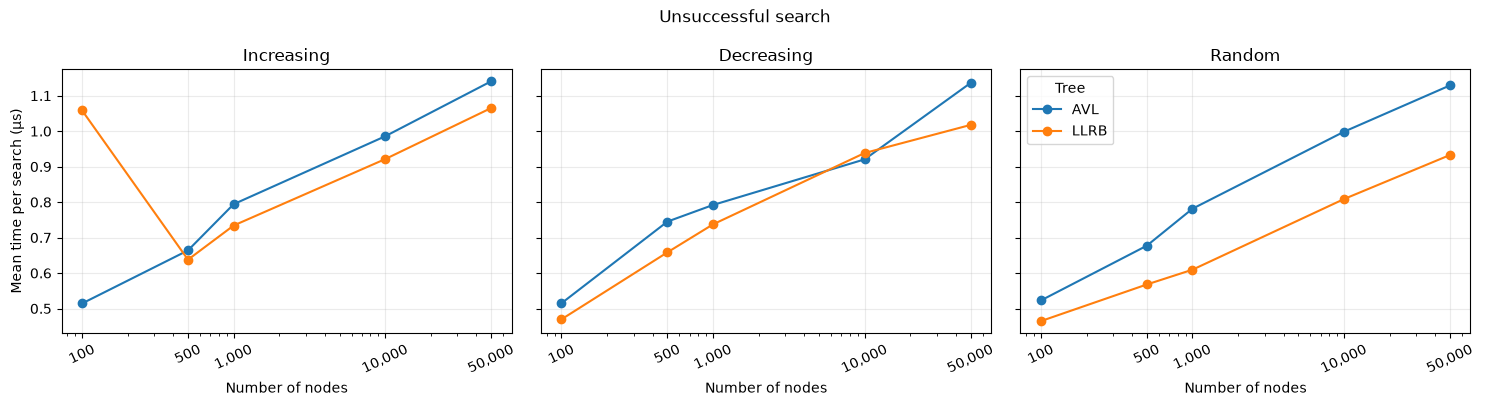

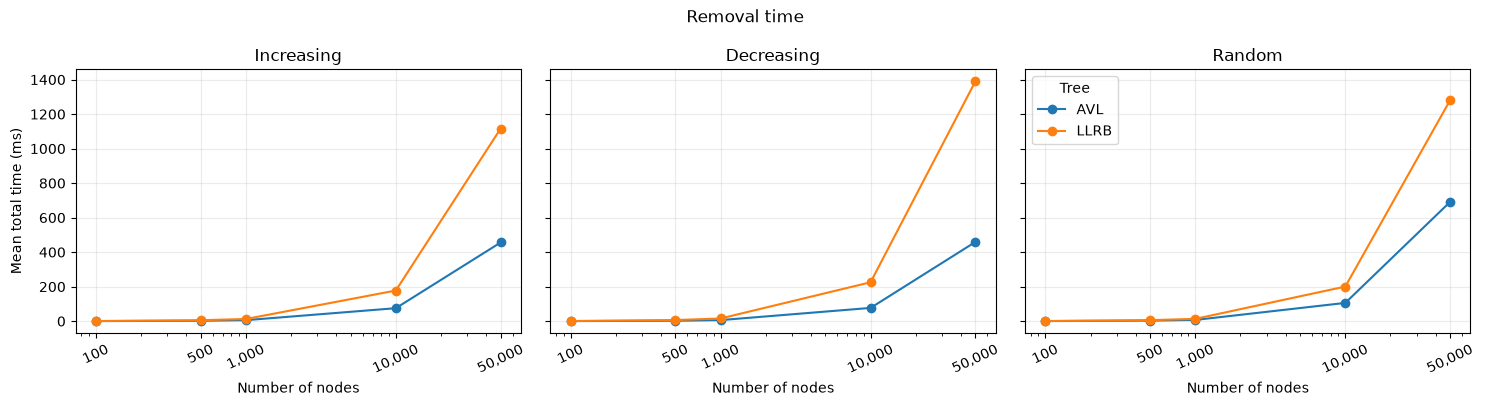

In [38]:
def plot_time_growth(df, metric, title, ylabel):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.1), sharey=True)
    for ax, scenario in zip(axes, SCENARIOS):
        subset = df[df["Sequence"] == scenario]
        for label in ["AVL", "LLRB"]:
            series = subset[subset["Tree"] == label].sort_values("Size")
            ax.plot(series["Size"], series[metric], marker="o", label=label)
        ax.set_xscale("log")
        ax.set_xticks(SIZES)
        ax.set_xticklabels([f"{n:,}" for n in SIZES], rotation=25)
        ax.set_title(scenario)
        ax.set_xlabel("Number of nodes")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(title="Tree")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_time_growth(summary_df, "Insertion_ms_mean", "Insertion time", "Mean total time (ms)")
plot_time_growth(summary_df, "Search_success_us_per_op_mean", "Successful search", "Mean time per search (µs)")
plot_time_growth(summary_df, "Search_failure_us_per_op_mean", "Unsuccessful search", "Mean time per search (µs)")
plot_time_growth(summary_df, "Removal_ms_mean", "Removal time", "Mean total time (ms)")

## 10. Intervalos de variação: média ± desvio-padrão

As barras representam um desvio-padrão em cada direção, não um intervalo de confiança. As comparações de tempo devem ser feitas levando em conta a variabilidade.

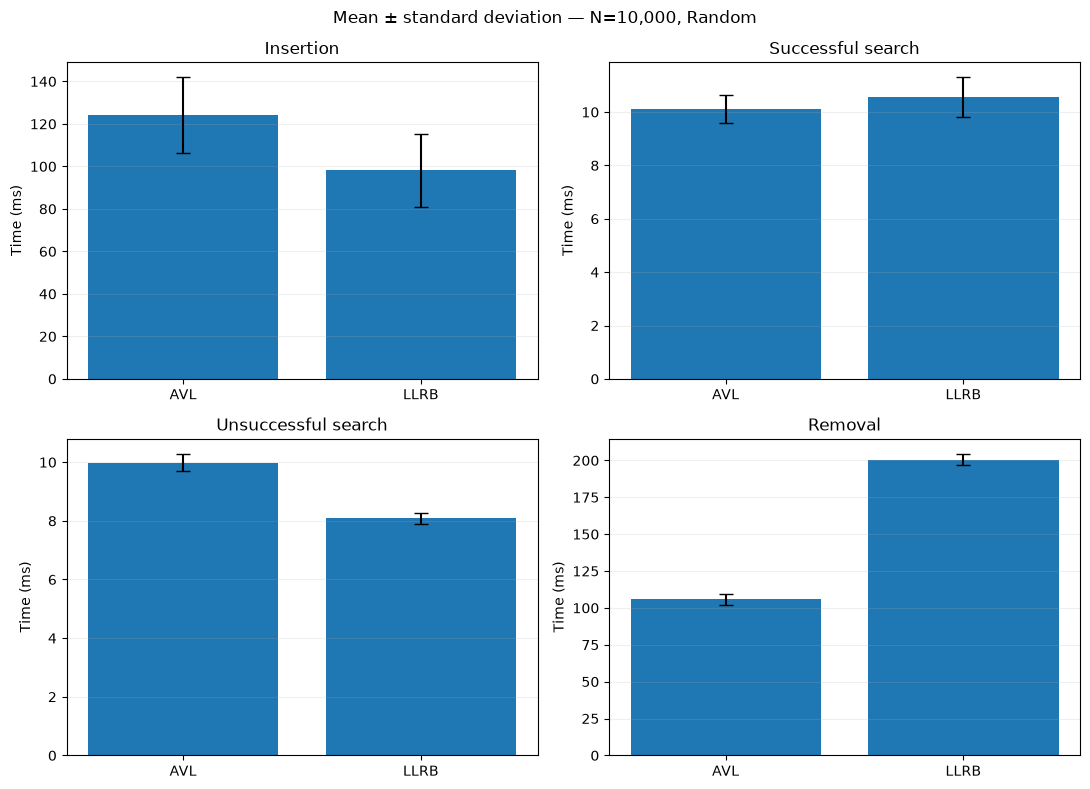

In [39]:
def plot_time_variability(df, size=10_000, scenario="Random"):
    columns = [
        ("Insertion_ms", "Insertion"),
        ("Search_success_ms", "Successful search"),
        ("Search_failure_ms", "Unsuccessful search"),
        ("Removal_ms", "Removal"),
    ]
    subset = df[(df["Size"] == size) & (df["Sequence"] == scenario)]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (col, title) in zip(axes.flat, columns):
        chunk = subset.set_index("Tree").reindex(["AVL", "LLRB"])
        ax.bar(["AVL", "LLRB"], chunk[f"{col}_mean"],
               yerr=chunk[f"{col}_std"], capsize=5)
        ax.set_title(title)
        ax.set_ylabel("Time (ms)")
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"Mean ± standard deviation — N={size:,}, {scenario}")
    plt.tight_layout()
    plt.show()

plot_time_variability(summary_df, size=10_000, scenario="Random")

## 11. Comparação direta: razão de tempo AVL / LLRB

Uma razão **maior que 1** indica que a AVL levou mais tempo (LLRB foi mais rápida naquele conjunto de medições). Uma razão **menor que 1** indica que 

In [40]:
ratio_columns = {
    "Insertion_ms_mean": "Insertion_AVL_over_LLRB",
    "Search_success_ms_mean": "Search_success_AVL_over_LLRB",
    "Search_failure_ms_mean": "Search_failure_AVL_over_LLRB",
    "Removal_ms_mean": "Removal_AVL_over_LLRB",
}

ratios = None
for metric, label in ratio_columns.items():
    wide = summary_df.pivot(index=["Size", "Sequence"], columns="Tree", values=metric)
    metric_ratio = (wide["AVL"] / wide["LLRB"]).rename(label).to_frame()
    ratios = metric_ratio if ratios is None else ratios.join(metric_ratio)

ratios_df = ratios.reset_index()
display(ratios_df.round(3))

,Size,Sequence,Insertion_AVL_over_LLRB,Search_success_AVL_over_LLRB,Search_failure_AVL_over_LLRB,Removal_AVL_over_LLRB
0,100,Decreasing,1.105,0.484,1.096,0.421
1,100,Increasing,1.478,1.125,0.486,0.482
2,100,Random,1.179,0.990,1.125,0.559
3,500,Decreasing,0.980,0.957,1.132,0.390
4,500,Increasing,1.400,0.941,1.041,0.455
5,500,Random,1.296,0.995,1.193,0.543
6,1000,Decreasing,0.341,0.995,1.074,0.396
7,1000,Increasing,1.406,0.892,1.082,0.459
8,1000,Random,1.265,0.998,1.282,0.534
9,10000,Decreasing,1.030,0.982,0.981,0.341


## 12. Testes adicionais de integridade após remoções intermediárias

Os benchmarks principais verificam a árvore depois de todas as inserções e após esvaziá-la. Este teste complementar verifica o balanceamento **após cada remoção**, com uma amostra controlada de até 500 valores por cenário. Isso detecta problemas que poderiam ser ocultados pelo estado final vazio.

In [41]:
INTEGRITY_SIZES = [100, 500]

for n in INTEGRITY_SIZES:
    for scenario, values in generate_sequences(n).items():
        for label, tree_class in TREE_CLASSES:
            tree = tree_class()
            for value in values:
                assert tree.insert(value)
                assert is_valid_tree(tree), f"Invalid {label} after insert {value}"
            for value in values:
                assert tree.remove(value)
                assert is_valid_tree(tree), f"Invalid {label} after remove {value}"
            assert tree.root is None
    print(f"Integrity checks passed for N={n}")

Integrity checks passed for N=100
Integrity checks passed for N=500


## 13. Exportar os resultados para CSV e figuras

Os arquivos são salvos em uma pasta `results/` ao lado do notebook. Os CSVs permitem recriar tabelas e gráficos posteriormente, sem repetir a bateria de testes. O notebook em si deve ser salvo com as saídas executadas se você quiser incluir os gráficos na apresentação.

In [42]:
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

results_df.to_csv(output_dir / "benchmark_raw.csv", index=False)
summary_df.to_csv(output_dir / "benchmark_summary.csv", index=False)
ratios_df.to_csv(output_dir / "benchmark_time_ratios.csv", index=False)

print("Saved:")
for file in sorted(output_dir.glob("*.csv")):
    print(" -", file)

Saved:
 - results\benchmark_raw.csv
 - results\benchmark_summary.csv
 - results\benchmark_time_ratios.csv


## 14. Análise dos resultados

# 14. Análise e interpretação dos resultados

## 14.1. Inserção

**Altura das árvores.** A AVL apresentou altura igual ou inferior à LLRB nos 15 cenários experimentais. Nas sequências crescentes, ambas produziram árvores de mesma altura em todos os tamanhos: 7, 9, 10, 14 e 16 níveis. Nas sequências decrescentes, as diferenças foram mais significativas, principalmente para 50.000 elementos, quando a AVL apresentou altura 16 e a LLRB atingiu 21. Nas sequências aleatórias, a AVL também apresentou estruturas mais compactas, com altura 19 para 50.000 elementos, em comparação à altura 22 da LLRB.

Esses resultados são compatíveis com o critério de balanceamento mais rigoroso da AVL, que limita a diferença de altura entre as subárvores de cada nó a uma unidade. A LLRB, por sua vez, mantém o balanceamento por meio das propriedades das ligações vermelhas e negras, admitindo diferenças maiores de altura convencional.

**Rotações e inversões de cores.** O número de rotações variou conforme a sequência de entrada. Para 50.000 elementos, os resultados foram:

| Sequência | Rotações AVL | Rotações LLRB | Inversões de cores LLRB |
|---|---:|---:|---:|
| Crescente | 49.984 | 49.985 | 49.979 |
| Decrescente | 49.984 | 49.979 | 49.979 |
| Aleatória | 34.802 | 59.456 | 37.288 |

Nas sequências ordenadas, as quantidades de rotações das duas estruturas foram próximas. Entretanto, na sequência aleatória, a LLRB realizou aproximadamente 71% mais rotações que a AVL. Isso demonstra que a variante Rubro-Negra implementada não necessariamente realiza menos rotações que a AVL.

As inversões de cores ocorreram exclusivamente na LLRB, constituindo um mecanismo adicional de manutenção de suas propriedades de balanceamento.

**Tempo de inserção.** A LLRB apresentou menor tempo médio de inserção em 12 dos 15 cenários analisados. Para 50.000 elementos, os resultados foram:

| Sequência | AVL — média ± desvio-padrão | LLRB — média ± desvio-padrão |
|---|---:|---:|
| Crescente | 749,91 ± 18,24 ms | 555,60 ± 44,54 ms |
| Decrescente | 682,06 ± 11,64 ms | 734,86 ± 9,79 ms |
| Aleatória | 853,63 ± 46,77 ms | 641,62 ± 21,68 ms |

A LLRB foi aproximadamente 1,35 vez mais rápida na inserção crescente e 1,33 vez mais rápida na inserção aleatória de 50.000 elementos. Na sequência decrescente, entretanto, a AVL apresentou vantagem, com tempo médio aproximadamente 7% inferior ao da LLRB.

A dispersão dos resultados também deve ser considerada. Destaca-se o cenário decrescente com 1.000 elementos, em que a LLRB apresentou média de 28,00 ms e desvio-padrão de 73,97 ms, sugerindo a ocorrência de medições atípicas e elevada variabilidade. Esse resultado se deve pois a média pode não representar adequadamente o comportamento típico daquela configuração.

De maneira geral, os tempos aumentaram com o tamanho da entrada, conforme esperado para a execução de múltiplas operações de inserção em árvores balanceadas. Os resultados indicam que, nesta implementação, a LLRB foi competitiva e frequentemente mais rápida na inserção, embora essa vantagem não tenha ocorrido em todas as sequências.

## 14.2. Busca

Os experimentos avaliaram buscas bem-sucedidas, realizadas para os elementos existentes nas árvores, e buscas malsucedidas, realizadas para valores não armazenados.

**Buscas bem-sucedidas.** Para 50.000 elementos, foram registrados:

| Sequência | AVL — tempo médio | LLRB — tempo médio |
|---|---:|---:|
| Crescente | 55,31 ms | 54,73 ms |
| Decrescente | 55,16 ms | 55,43 ms |
| Aleatória | 82,69 ms | 87,15 ms |

Na sequência crescente, a LLRB apresentou uma vantagem pequena. Na decrescente e na aleatória, a AVL foi mais rápida, com maior diferença na sequência aleatória. Contudo, mesmo nesse último caso, as médias devem ser interpretadas em conjunto com os desvios-padrão, que foram de 7,23 ms na AVL e 6,01 ms na LLRB.

Portanto, os resultados não permitem afirmar que a menor altura da AVL conduz obrigatoriamente a buscas mais rápidas. O tempo observado também depende da distribuição dos elementos, dos caminhos efetivamente percorridos e dos custos da implementação Python.

**Buscas malsucedidas.** Para 50.000 elementos, os resultados foram:

| Sequência | AVL — tempo médio | LLRB — tempo médio |
|---|---:|---:|
| Crescente | 57,02 ms | 53,26 ms |
| Decrescente | 56,79 ms | 50,88 ms |
| Aleatória | 56,44 ms | 46,64 ms |

A LLRB apresentou menor tempo médio de busca malsucedida nos três cenários com 50.000 elementos. Na sequência aleatória, sua vantagem foi de aproximadamente 17% em relação à AVL.

É importante destacar uma limitação metodológica: todos os valores procurados eram maiores que o maior elemento inserido. Portanto, o teste mediu especificamente buscas direcionadas à extremidade direita das árvores. Não se trata de uma amostra representativa de todas as buscas malsucedidas possíveis.

Essa característica também ajuda a explicar por que a árvore de menor altura total nem sempre apresentou a busca malsucedida mais rápida: a altura global não descreve necessariamente a profundidade do caminho mais à direita.

De modo geral, os tempos de busca apresentaram diferenças relativamente pequenas e resultados variados. As duas estruturas mantiveram desempenho compatível com sua complexidade assintótica logarítmica, sem que uma delas demonstrasse superioridade consistente em todos os tipos de busca.

## 14.3. Remoção

A remoção apresentou as diferenças mais expressivas entre as implementações. A AVL realizou menos rotações e apresentou menor tempo médio de remoção em todos os 15 cenários experimentais.

**Quantidade de rotações.** Para 50.000 elementos, os resultados foram:

| Sequência | Rotações AVL | Rotações LLRB | Inversões de cores LLRB |
|---|---:|---:|---:|
| Crescente | 24.985 | 49.989 | 579.759 |
| Decrescente | 24.985 | 614.181 | 579.759 |
| Aleatória | 19.874 | 324.232 | 570.640 |

A diferença foi especialmente elevada nas sequências decrescentes e aleatórias. Na remoção decrescente de 50.000 elementos, a LLRB executou aproximadamente 24,6 vezes mais rotações que a AVL.

Esse comportamento está associado às estratégias de manutenção das propriedades das estruturas. A AVL realiza atualizações de altura e rotações quando detecta desequilíbrios. Já a remoção LLRB utiliza transformações preventivas ao longo da recursão, envolvendo rotações e inversões de cores para preservar a altura negra e a orientação das ligações vermelhas.

**Tempo de remoção.** Para 50.000 elementos, foram obtidos:

| Sequência | AVL — média ± desvio-padrão | LLRB — média ± desvio-padrão |
|---|---:|---:|
| Crescente | 456,15 ± 2,25 ms | 1.116,64 ± 11,85 ms |
| Decrescente | 459,12 ± 2,65 ms | 1.390,11 ± 32,32 ms |
| Aleatória | 691,58 ± 14,37 ms | 1.281,17 ± 9,78 ms |

A LLRB apresentou tempo médio aproximadamente 2,45 vezes maior na sequência crescente, 3,03 vezes maior na decrescente e 1,85 vez maior na aleatória.

A vantagem da AVL ocorreu em todos os tamanhos testados, incluindo 100, 500, 1.000, 10.000 e 50.000 elementos. Embora ambas tenham apresentado aumento do tempo total com o crescimento da entrada, a AVL manteve desempenho superior na remoção.

Entretanto, é necessário considerar uma diferença entre as implementações. O método público `remove()` da LLRB realiza uma busca prévia para confirmar a existência do elemento antes de executar a remoção balanceada. Na AVL, essa busca prévia não é realizada separadamente. Assim, parte da diferença temporal pode decorrer dessa decisão de implementação, além do número maior de rotações e inversões de cores.

Portanto, os resultados sustentam a conclusão de que a implementação AVL desenvolvida neste projeto foi mais eficiente na remoção para os cenários avaliados, sem permitir generalizar essa superioridade para todas as variantes e implementações de árvores Rubro-Negras.

## 14.4. Limitações dos experimentos

Os experimentos foram realizados em Python, em um mesmo computador e em uma única sessão, considerando cinco tamanhos de entrada e três padrões de organização dos valores. Embora essas configurações permitam observar tendências relevantes, não representam todas as distribuições de dados e cargas de trabalho possíveis.

O número de repetições variou conforme o tamanho da entrada: 25 para 100 elementos, 20 para 500, 15 para 1.000, 10 para 10.000 e 5 para 50.000. Dessa forma, os experimentos maiores possuem menos observações para caracterizar a variabilidade dos tempos.

As medições também estão sujeitas a interferências do interpretador Python, do sistema operacional, do gerenciamento de memória e de outras atividades computacionais. Essa limitação é particularmente relevante quando os tempos são pequenos ou quando o desvio-padrão é elevado.

Além disso, a remoção foi executada na mesma ordem em que os valores foram inseridos. As buscas malsucedidas foram realizadas exclusivamente com valores superiores ao máximo armazenado, restringindo sua interpretação aos caminhos da extremidade direita das árvores.

Os tempos medidos também refletem decisões concretas de implementação, incluindo o comportamento dos métodos públicos, os laços de execução e as verificações internas. Assim, os resultados não representam exclusivamente o custo abstrato de cada operação.

Por fim, todas as 450 execuções foram registradas como válidas, fornecendo evidências favoráveis à correção funcional das implementações nos cenários testados. Entretanto, a aprovação desses testes não constitui prova formal de correção para todas as entradas possíveis.

## 14.5. Conclusão

Os resultados experimentais demonstraram que ambas as estruturas mantiveram alturas reduzidas em relação ao número de elementos, comportamento compatível com a complexidade assintótica \(O(\log n)\) das operações de busca, inserção e remoção.

A AVL apresentou árvores de altura igual ou inferior às da LLRB em todos os cenários, confirmando empiricamente o efeito de seu critério mais rigoroso de balanceamento.

Na inserção, a LLRB apresentou menores tempos médios na maioria das combinações avaliadas, apesar de realizar mais rotações em determinadas sequências, especialmente nas aleatórias. Isso indica que a contagem de rotações, isoladamente, não é suficiente para determinar o desempenho temporal de uma implementação.

Nas buscas, os resultados foram menos uniformes. A AVL obteve vantagens em alguns cenários de busca bem-sucedida, enquanto a LLRB se destacou em várias buscas malsucedidas, principalmente para entradas maiores. A altura global da árvore não determinou, isoladamente, a velocidade das buscas.

Na remoção, a AVL apresentou vantagem consistente, tanto em tempo médio quanto em quantidade de rotações. A LLRB realizou um número substancialmente maior de ajustes estruturais e inversões de cores, sobretudo com entradas decrescentes e aleatórias.

Conclui-se que não existe uma estrutura universalmente superior em todas as operações. Para as implementações e condições deste estudo, a LLRB mostrou-se competitiva na inserção, enquanto a AVL apresentou maior compactação estrutural e desempenho consistentemente superior na remoção.

A análise evidencia que a complexidade assintótica é fundamental para compreender o comportamento das estruturas, mas os resultados práticos também dependem da ordem dos dados, dos mecanismos de balanceamento e das escolhas de implementação. Assim, a seleção de uma estrutura deve considerar não apenas sua complexidade teórica, mas também o perfil das operações predominantes na aplicação.